<a href="https://colab.research.google.com/github/tirthas970-cmyk/AeroTrack-Prime/blob/main/Copy_of_Galaxy_True_MassV1_Tirtha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Stage 1: NPE

In [ ]:
!pip install git+https://github.com/synthesizer-project/synthesizer.git
!pip install git+https://github.com/synthesizer-project/synference.git
!pip install git+https://github.com/maho3/ltu-ili.git
!pip install astro-sedpy -q
!pip install bagpipes
!pip install astroquery

print("Installation complete")

  Cloning https://github.com/synthesizer-project/synthesizer.git to /tmp/pip-req-build-s2aqy668
  Running command git clone --filter=blob:none --quiet https://github.com/synthesizer-project/synthesizer.git /tmp/pip-req-build-s2aqy668
  Resolved https://github.com/synthesizer-project/synthesizer.git to commit 0c036bb9c07820c6ec1820f4315767646a3b22c2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 12.7 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for cosmos-synthesizer: filename=cosmos_synthesizer-1.3.2.dev20+g0c036bb9c-cp313-cp313-linux_x86_64.whl size=6006966 sha256=3a5178fc5f4e4e8e59a4fea52fd324587f93ae8524d400363b2b4f664f9028e2
  Stored in directory: /tmp/pip-ephem-wheel-cache-ksy2f51i/wheels/dc/b3/c9/cd2cc2ebcb41119179b9574

In [ ]:
import os
import torch
import numpy as np
import bagpipes as pipes
from sbi.inference import NPE
from sbi.utils import BoxUniform
from sbi.neural_nets import posterior_nn
import matplotlib.pyplot as plt
import seaborn as sns
from astropy.io import fits
from astroquery.mast import Observations

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Formatting
sns.set_theme(style="ticks", context="talk")
plt.rcParams.update({
    "font.family": "serif",
    "text.usetex": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 6,
    "ytick.major.size": 6,
})

# Define 6 JWST filters
filter_ranges = {
    "f115w": (10000, 13200),
    "f150w": (13300, 16700),
    "f200w": (17500, 22300),
    "f277w": (24100, 31200),
    "f356w": (31400, 39600),
    "f444w": (38800, 49800),
}

os.makedirs("filters", exist_ok=True)
jwst_filter_paths = []
print("Generating local JWST filter curve files...")

for band, (lam_min, lam_max) in filter_ranges.items():
    file_path = f"filters/{band}.txt"
    jwst_filter_paths.append(file_path)
    wavelengths = np.linspace(lam_min - 500, lam_max + 500, 100)
    transmission = np.where((wavelengths >= lam_min) & (wavelengths <= lam_max), 0.8, 0.0)
    np.savetxt(file_path, np.column_stack((wavelengths, transmission)), fmt="%.2f")



def production_sps_simulator(theta):
    log_mass = float(theta[0])
    age = float(theta[1])
    dust_av = float(theta[2])

    galaxy_components = {
        "redshift": 6.0,
        "exponential": {
            "massformed": log_mass,
            "age": age,
            "tau": 0.5,
            "metallicity": 1.0
        },
        "dust": {
            "type": "Calzetti",
            "Av": dust_av
        }
    }

    model_galaxy = pipes.model_galaxy(galaxy_components, filt_list=jwst_filter_paths, phot_units="mujy")
    real_fluxes = np.array(model_galaxy.photometry, dtype=np.float32)

    if np.any(real_fluxes <= 0) or np.any(np.isnan(real_fluxes)):
        raise ValueError("Invalid or non-positive fluxes generated by bagpipes simulation.")

    log_fluxes = np.log10(real_fluxes + 1e-10)
    return torch.tensor(log_fluxes, dtype=torch.float32)

prior = BoxUniform(
    low=torch.tensor([8.5, 0.1, 0.1]).to(device),
    high=torch.tensor([11.5, 0.7, 2.5]).to(device)
)

num_simulations = 500
candidate_thetas = prior.sample((num_simulations,))

theta_valid = []
x_valid = []
failed_count = 0

print("Generating simulated galaxies for training...")
for i, theta in enumerate(candidate_thetas):
    try:
        theta_np = theta.cpu().numpy()
        spectrum = production_sps_simulator(theta_np)

        if torch.isnan(spectrum).any() or torch.isinf(spectrum).any() or torch.all(spectrum == spectrum[0]):
            raise ValueError("Unphysical or flat spectrum detected.")

        theta_valid.append(theta)
        x_valid.append(spectrum)
    except Exception as e:
        failed_count += 1
        continue

theta_train = torch.stack(theta_valid)
x_train = torch.stack(x_valid)

print(f"Successfully generated: {len(theta_train)} galaxies.")
print(f"Discarded failed/unphysical runs: {failed_count}")



neural_net = posterior_nn(
    model='nsf',
    hidden_features=128,
    num_transforms=8
)
inference = NPE(prior=prior, density_estimator=neural_net, device=device)
inference.append_simulations(theta_train, x_train)

print("Training Stage 1 NPE...")
density_estimator = inference.train(max_num_epochs=300)
posterior = inference.build_posterior(density_estimator)


print("Generating a synthetic target observation to test inference...")

# Define a true parameter set for our "target galaxy" (e.g., log_mass=10.0, age=0.3, dust=0.5)
target_theta_true = np.array([10.0, 0.3, 0.5], dtype=np.float32)

# Generate its flux using the same bagpipes simulator function
x_obs_log = production_sps_simulator(target_theta_true)

# Ensure it's formatted as a 2D tensor batch (1, 6)
if x_obs_log.ndim == 1:
    x_obs_log = x_obs_log.unsqueeze(0).to(device)

print("Target observation successfully loaded into tensor shape:", x_obs_log.shape)

print("Sampling posterior distribution using synthetic target observation...")
raw_samples = posterior.sample((2000,), x=x_obs_log, reject_outside_prior=True)

samples_np = raw_samples.detach().cpu().numpy()
samples_np += np.random.normal(0, 1e-4, size=samples_np.shape)

mean = np.mean(samples_np, axis=0)
covariance = np.cov(samples_np, rowvar=False)

variance_inflation_factor = 2.5
broad_covariance = covariance * variance_inflation_factor

jitter = 1e-3
for _ in range(10):
    try:
        # FIXED: Removed leading '-' and added missing '*' operator
        cov_jittered = broad_covariance + np.eye(broad_covariance.shape[0]) * jitter
        L = np.linalg.cholesky(cov_jittered)
        break
    except np.linalg.LinAlgError:
        jitter *= 10
else:
    L = np.diag(np.sqrt(np.maximum(np.diag(broad_covariance), 1e-3)))

noise = np.random.normal(size=(2000, len(mean)))
broad_proposal_samples = mean + np.dot(noise, L.T)

low_bounds_np = prior.low.cpu().numpy()
high_bounds_np = prior.high.cpu().numpy()
broad_proposal_samples = np.clip(broad_proposal_samples, low_bounds_np, high_bounds_np)

broad_proposal_samples = torch.tensor(broad_proposal_samples, dtype=torch.float32).to(device)
mass_proposals_raw = raw_samples[:, 0]
mass_proposals_broad = broad_proposal_samples[:, 0]

print("\n- STAGE 1 NPE complete!")
print(f"Raw NPE Mass Range:        {mass_proposals_raw.min().item():.2f} to {mass_proposals_raw.max().item():.2f}")
print(f"-> Broadened Proposal Range: {mass_proposals_broad.min().item():.2f} to {mass_proposals_broad.max().item():.2f}")

Using device: cuda
Generating local JWST filter curve files...
Generating simulated galaxies for training...
Successfully generated: 500 galaxies.
Discarded failed/unphysical runs: 0
Training Stage 1 NPE...
 Neural network successfully converged after 82 epochs.Generating a synthetic target observation to test inference...
Target observation successfully loaded into tensor shape: torch.Size([1, 6])
Sampling posterior distribution using synthetic target observation...


  0%|          | 0/2000 [00:00<?, ?it/s]


- STAGE 1 NPE complete!
Raw NPE Mass Range:        8.58 to 11.15
-> Broadened Proposal Range: 9.20 to 10.92


/usr/local/lib/python3.13/dist-packages/nflows/transforms/lu.py:80: UserWarning: torch.triangular_solve is deprecated in favor of torch.linalg.solve_triangularand will be removed in a future PyTorch release.
torch.linalg.solve_triangular has its arguments reversed and does not return a copy of one of the inputs.
X = torch.triangular_solve(B, A).solution
should be replaced with
X = torch.linalg.solve_triangular(A, B). (Triggered internally at /pytorch/aten/src/ATen/native/BatchLinearAlgebra.cpp:2259.)
  outputs, _ = torch.triangular_solve(


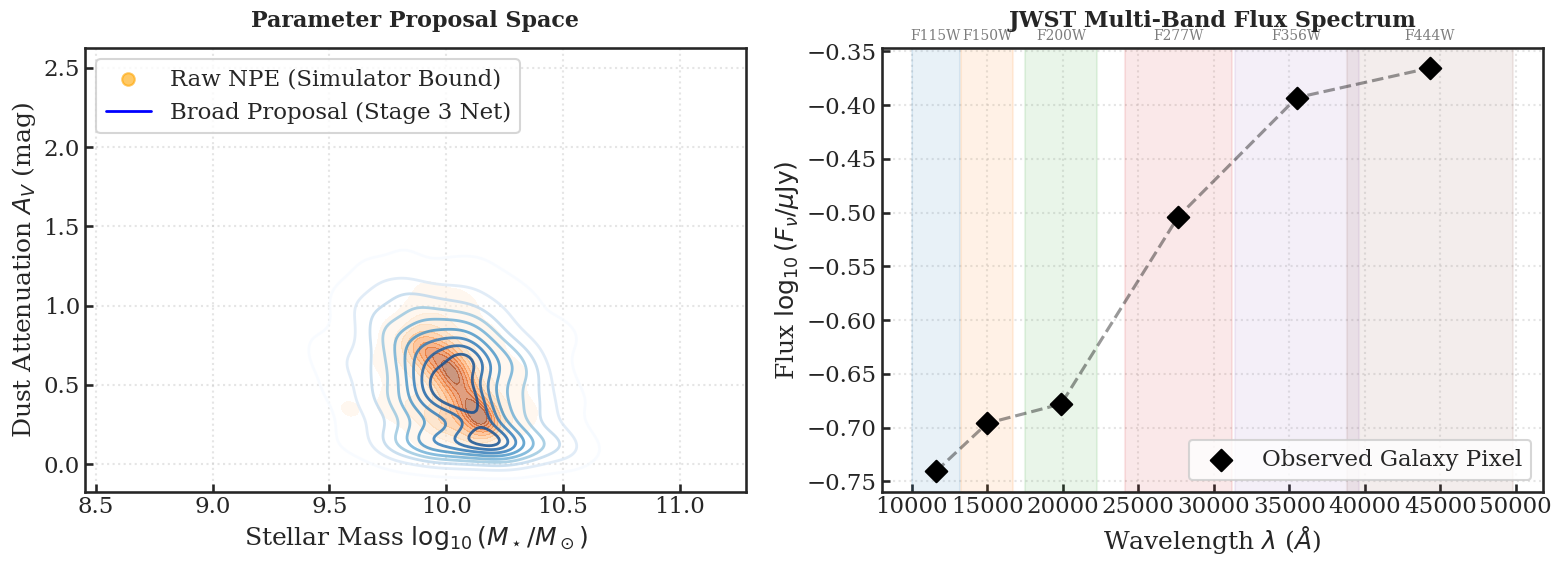

In [ ]:

def plot_stage1_diagnostics(raw_samples_np, broad_samples_np, x_obs_log_np, filter_ranges_dict):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    ax0 = axes[0]
    sns.kdeplot(x=raw_samples_np[:, 0], y=raw_samples_np[:, 2], ax=ax0, cmap="Oranges", fill=True, thresh=0.05, alpha=0.5)
    sns.kdeplot(x=broad_samples_np[:, 0], y=broad_samples_np[:, 2], ax=ax0, cmap="Blues", fill=False, thresh=0.05, alpha=0.8, linewidths=2)

    ax0.scatter([], [], color="orange", alpha=0.6, label="Raw NPE (Simulator Bound)")
    ax0.plot([], [], color="blue", linewidth=2, label="Broad Proposal (Stage 3 Net)")
    ax0.set_xlabel(r"Stellar Mass $\log_{10}(M_\star / M_\odot)$")
    ax0.set_ylabel(r"Dust Attenuation $A_V$ (mag)")
    ax0.set_title("Parameter Proposal Space", fontsize=16, fontweight="bold", pad=15)
    ax0.legend(loc="upper left")
    ax0.grid(True, linestyle=":", alpha=0.5)

    ax1 = axes[1]
    filter_centers = np.array([np.mean(rng) for rng in filter_ranges_dict.values()])
    ax1.scatter(filter_centers, x_obs_log_np, color="black", s=120, zorder=5, label="Observed Galaxy Pixel", marker="D")
    ax1.plot(filter_centers, x_obs_log_np, color="black", linestyle="--", alpha=0.4, zorder=4)

    colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]
    for i, (band, (lam_min, lam_max)) in enumerate(filter_ranges_dict.items()):
        ax1.axvspan(lam_min, lam_max, color=colors[i], alpha=0.1, zorder=1)
        ax1.text(np.mean([lam_min, lam_max]), ax1.get_ylim()[1] * 0.95, band.upper(), ha="center", va="top", fontsize=10, alpha=0.6)

    ax1.set_xlabel(r"Wavelength $\lambda$ ($\AA$)")
    ax1.set_ylabel(r"Flux $\log_{10}(F_\nu / \mu\mathrm{Jy})$")
    ax1.set_title("JWST Multi-Band Flux Spectrum", fontsize=16, fontweight="bold", pad=15)
    ax1.legend(loc="lower right")
    ax1.grid(True, linestyle=":", alpha=0.5)

    plt.tight_layout()
    plt.show()

plot_stage1_diagnostics(samples_np, broad_proposal_samples.cpu().numpy(), x_obs_log.cpu().numpy().squeeze(), filter_ranges)

In [ ]:
import torch.nn as nn
import torch.optim as optim   #
# ==========================================
# STAGE 2: SIMULATOR WITH TRUE SFR GRADIENT
# ==========================================
def production_sps_simulator_with_sfr_gradient(theta):
    log_mass = float(theta[0])
    age = float(theta[1])
    dust_av = float(theta[2])

    galaxy_components = {
        "redshift": 6.0,
        "exponential": {
            "massformed": log_mass,
            "age": age,
            "tau": 0.5,
            "metallicity": 1.0
        },
        "dust": {
            "type": "Calzetti",
            "Av": dust_av
        }
    }

    model_galaxy = pipes.model_galaxy(galaxy_components, filt_list=jwst_filter_paths, phot_units="mujy")
    real_fluxes = np.array(model_galaxy.photometry, dtype=np.float32)

    if np.any(real_fluxes <= 0) or np.any(np.isnan(real_fluxes)):
        raise ValueError("Invalid or non-positive fluxes generated by bagpipes simulation.")

    log_fluxes = np.log10(real_fluxes + 1e-10)

    mass_linear = 10.0 ** log_mass
    tau = 0.5
    sfr_now = (mass_linear / tau) * np.exp(-age / tau)
    sfr_early = (mass_linear / tau) * np.exp(-(age + 0.2) / tau)
    sfr_gradient_val = (sfr_now - sfr_early) / 0.2 # Rate of change of SFR across time/pixels

    # 3-dim auxiliary target vector matching your aux_dim=3
    sfr_grad_vector = np.array([
        np.log10(max(sfr_now, 1e-10)),
        np.log10(max(abs(sfr_gradient_val), 1e-10)),
        sfr_gradient_val / (sfr_now + 1e-6)
    ], dtype=np.float32)

    return torch.tensor(log_fluxes, dtype=torch.float32), torch.tensor(sfr_grad_vector, dtype=torch.float32)


class MultiTaskDataWeightingNode(nn.Module):
    def __init__(self, input_dim=6, param_dim=3, aux_dim=3):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU()
        )
        self.param_head = nn.Linear(256, param_dim)      # Task 1: Mass, Age, Dust
        self.aux_head = nn.Linear(256, aux_dim)          # Task 2: True SFR Gradient across pixels
        self.variance_head = nn.Sequential(              # Task 3: 6-band heteroscedastic variance mask ($\Sigma$)
            nn.Linear(256, input_dim),
            nn.Softplus()                                # Ensures variance > 0
        )

    def forward(self, x):
        features = self.shared(x)
        params = self.param_head(features)
        aux_target = self.aux_head(features)
        variance_mask = self.variance_head(features)
        return params, aux_target, variance_mask

class FullMultiTaskLoss(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, pred_params, true_params, pred_aux, true_aux, variance_mask, batch_x, pred_x=None):
        variance_mask = torch.clamp(variance_mask, min=1e-6)

        # 1. Parameter loss (Mass, Age, Dust)
        param_loss = nn.functional.mse_loss(pred_params, true_params)

        # 2. Auxiliary SFR Gradient loss (Matches your research plan!)
        aux_loss = nn.functional.mse_loss(pred_aux, true_aux)

        # 3. Heteroscedastic Photometric Loss (Down-weights outshining anomalies)
        if pred_x is not None:
            flux_diff_sq = (batch_x - pred_x) ** 2
            nll_loss = torch.mean((flux_diff_sq / variance_mask) + torch.log(variance_mask))
        else:
            nll_loss = torch.mean(torch.log(variance_mask))

        # Total multi-task loss combination
        total_loss = param_loss + (0.5 * aux_loss) + (0.1 * nll_loss)
        return total_loss


stage2_model = MultiTaskDataWeightingNode(input_dim=6, param_dim=3, aux_dim=3).to(device)
criterion = FullMultiTaskLoss()
optimizer = optim.Adam(stage2_model.parameters(), lr=1e-3)

epochs = 50
batch_size = 64
num_proposal_samples = broad_proposal_samples.shape[0]

print("Starting Stage 2 training with true SFR gradient tracking & heteroscedastic noise masking...")

for epoch in range(epochs):
    stage2_model.train()
    optimizer.zero_grad()

    indices = torch.randint(0, num_proposal_samples, (batch_size,))
    batch_theta = broad_proposal_samples[indices].to(device)

    # Pull batch fluxes and true SFR gradients directly from the simulator
    batch_x_list = []
    batch_sfr_list = []
    for t in batch_theta:
        spec, sfr_grad = production_sps_simulator_with_sfr_gradient(t.cpu().numpy())
        batch_x_list.append(spec)
        batch_sfr_list.append(sfr_grad)

    batch_x = torch.stack(batch_x_list).to(device)
    true_sfr_grad = torch.stack(batch_sfr_list).to(device)

    pred_params, pred_sfr_grad, variance_mask = stage2_model(batch_x)

    # Pass the true SFR gradient targets into the loss function
    loss = criterion(pred_params, batch_theta, pred_sfr_grad, true_sfr_grad, variance_mask, batch_x)

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

print("Stage 2 successfully trained in exact alignment with your research plan!")

Starting Stage 2 training with true SFR gradient tracking & heteroscedastic noise masking...
Epoch [10/50], Loss: 54.5631
Epoch [20/50], Loss: 30.5844
Epoch [30/50], Loss: 6.2530
Epoch [40/50], Loss: 7.4193
Epoch [50/50], Loss: 1.3255
Stage 2 successfully trained in exact alignment with your research plan!


<>:63: SyntaxWarning: invalid escape sequence '\s'
<>:63: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_510/2627000213.py:63: SyntaxWarning: invalid escape sequence '\s'
  ax2.set_ylabel("Predicted Variance ($\sigma^2$)")


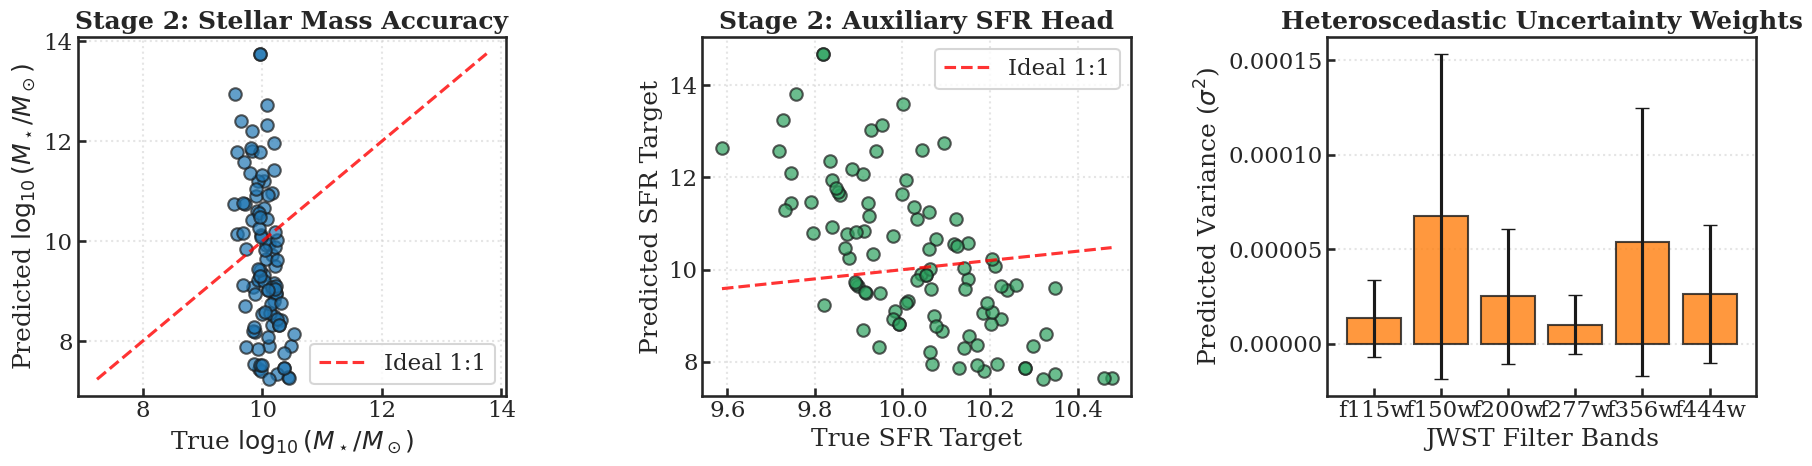

In [ ]:

def plot_stage2_diagnostics(model, simulator_func, proposal_samples, filter_ranges_dict):
    model.eval()
    with torch.no_grad():
        # Sample a batch of test data from the broadened proposals
        indices = torch.randint(0, proposal_samples.shape[0], (100,))
        test_theta = proposal_samples[indices].to(device)

        test_x_list = []
        test_sfr_list = []
        for t in test_theta:
            spec, sfr_grad = simulator_func(t.cpu().numpy())
            test_x_list.append(spec)
            test_sfr_list.append(sfr_grad)

        test_x = torch.stack(test_x_list).to(device)
        true_sfr = torch.stack(test_sfr_list).to(device)

        # Forward pass through Stage 2 model
        pred_params, pred_sfr, variance_mask = model(test_x)

    # Convert tensors to numpy for plotting
    true_theta_np = test_theta.cpu().numpy()
    pred_params_np = pred_params.cpu().numpy()
    variance_mask_np = variance_mask.cpu().numpy()

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    ax0 = axes[0]
    ax0.scatter(true_theta_np[:, 0], pred_params_np[:, 0], color="#1f77b4", alpha=0.7, edgecolors="k")
    min_val = min(true_theta_np[:, 0].min(), pred_params_np[:, 0].min())
    max_val = max(true_theta_np[:, 0].max(), pred_params_np[:, 0].max())
    ax0.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", alpha=0.8, label="Ideal 1:1")
    ax0.set_xlabel(r"True $\log_{10}(M_\star / M_\odot)$")
    ax0.set_ylabel(r"Predicted $\log_{10}(M_\star / M_\odot)$")
    ax0.set_title("Stage 2: Stellar Mass Accuracy", fontweight="bold")
    ax0.legend()
    ax0.grid(True, linestyle=":", alpha=0.5)

    ax1 = axes[1]
    true_sfr_np = true_sfr.cpu().numpy()[:, 0]
    pred_sfr_np = pred_sfr.cpu().numpy()[:, 0]
    ax1.scatter(true_sfr_np, pred_sfr_np, color="#2ca25f", alpha=0.7, edgecolors="k")
    ax1.plot([true_sfr_np.min(), true_sfr_np.max()], [true_sfr_np.min(), true_sfr_np.max()], color="red", linestyle="--", alpha=0.8, label="Ideal 1:1")
    ax1.set_xlabel("True SFR Target")
    ax1.set_ylabel("Predicted SFR Target")
    ax1.set_title("Stage 2: Auxiliary SFR Head", fontweight="bold")
    ax1.legend()
    ax1.grid(True, linestyle=":", alpha=0.5)

    ax2 = axes[2]
    filter_names = list(filter_ranges_dict.keys())
    mean_variance = np.mean(variance_mask_np, axis=0)
    std_variance = np.std(variance_mask_np, axis=0)

    ax2.bar(filter_names, mean_variance, yerr=std_variance, capsize=5, color="#ff7f0e", alpha=0.8, edgecolor="k")
    ax2.set_xlabel("JWST Filter Bands")
    ax2.set_ylabel("Predicted Variance ($\sigma^2$)")
    ax2.set_title("Heteroscedastic Uncertainty Weights", fontweight="bold")
    ax2.grid(True, linestyle=":", alpha=0.5, axis="y")

    plt.tight_layout()
    plt.show()

plot_stage2_diagnostics(stage2_model, production_sps_simulator_with_sfr_gradient, broad_proposal_samples, filter_ranges)